# 04 - Data mining / machine learning (KDD stage 4) - real data
Trains and compares models that forecast **tomorrow's heavy-rain day** (>= 10 mm) from today's weather.

| Model | Why it is here |
|---|---|
| **Always "no heavy rain"** | the do-nothing reference; shows why accuracy alone is misleading |
| **Persistence** | "if it was heavy today, it will be heavy tomorrow" - the simplest real forecast |
| **Logistic regression** | transparent linear model on standardised features |
| **Random forest** | non-linear, robust on small tabular data |
| **Gradient boosting** | shallow boosted trees, usually the strongest tabular learner |

Evaluation protocol (fixed before looking at results):
1. **Hold-out:** fit on the train split, choose the decision threshold on validation (maximise F1), report once on test.
2. **Walk-forward:** the year is cut into 6 date blocks; models are refit on all earlier blocks and scored on the next one
   (4 folds). This uses far more positive days than the small test split, so it is the more trustworthy number.
3. **Bootstrap 95% intervals** on the test scores, to show how much a handful of positive days can move a metric.

Hyperparameters are small fixed values chosen for a tiny dataset; they are not tuned on the test data.

In [1]:
import sys
from pathlib import Path


def _find_helpers():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base / "notebooks" / "real_data"):
            if (cand / "weather_data.py").is_file():
                return cand
    raise SystemExit("weather_data.py not found. Open this notebook from inside the repository.")


sys.path.insert(0, str(_find_helpers()))

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

import weather_data as wd

SEED = wd.SEED
ROOT = wd.find_root()
OUT = wd.out_dir(ROOT)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

feat = pd.read_csv(OUT / "weather_features.csv", parse_dates=["date"])
fmeta = json.loads((OUT / "weather_features.meta.json").read_text())
FEATURES = fmeta["scaler"]["features"]
MEAN = pd.Series(fmeta["scaler"]["mean"])
STD = pd.Series(fmeta["scaler"]["std"])
tr, va, te = (feat[feat["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
print({s: (len(d), int(d["y"].sum())) for s, d in (("train", tr), ("val", va), ("test", te))}, "(rows, positives)")


def scaled(d):
    return ((d[FEATURES] - MEAN) / STD).to_numpy()

{'train': (464, 30), 'val': (156, 17), 'test': (156, 8)} (rows, positives)


## 1. Models and metrics

In [2]:
def make_model(name):
    if name == "logistic_regression":
        return LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000, random_state=SEED)
    if name == "random_forest":
        return RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=5,
                                      class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    if name == "gradient_boosting":
        return GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05,
                                          subsample=0.8, random_state=SEED)
    raise KeyError(name)


LEARNED = ["logistic_regression", "random_forest", "gradient_boosting"]
HEAVY = fmeta["heavy_rain_mm"]


def fit_predict(name, train_df, test_df):
    """Probability of a heavy-rain day tomorrow for each row of test_df."""
    X_tr = scaled(train_df) if name == "logistic_regression" else train_df[FEATURES].to_numpy()
    X_te = scaled(test_df) if name == "logistic_regression" else test_df[FEATURES].to_numpy()
    model = make_model(name).fit(X_tr, train_df["y"])
    return model, model.predict_proba(X_te)[:, 1]


def persistence_score(d):
    """Not a probability: today's rain in mm. Higher means more likely; threshold = HEAVY mm."""
    return d["rainfall_mm"].to_numpy()


def best_threshold(y, p):
    grid = np.unique(np.quantile(p, np.linspace(0.5, 0.995, 120)))
    scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))])


def metrics(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    return {
        "threshold": float(thr),
        "roc_auc": float(roc_auc_score(y, p)),
        "avg_precision": float(average_precision_score(y, p)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
        "accuracy": float((pred == np.asarray(y)).mean()),
        "confusion_matrix": confusion_matrix(y, pred, labels=[0, 1]).tolist(),
    }

## 2. Hold-out evaluation (train -> validation threshold -> test)

In [3]:
holdout, test_scores, models = {}, {}, {}
y_te = te["y"].to_numpy()

# reference: always predict "no heavy rain"
holdout["always_no"] = {"accuracy": float(1 - y_te.mean()), "recall": 0.0, "precision": 0.0, "f1": 0.0,
                        "roc_auc": 0.5, "avg_precision": float(y_te.mean()), "balanced_accuracy": 0.5,
                        "threshold": None, "confusion_matrix": [[int((y_te == 0).sum()), 0], [int(y_te.sum()), 0]]}

# persistence: today's rain >= 10 mm  ->  heavy tomorrow
test_scores["persistence"] = persistence_score(te)
holdout["persistence"] = metrics(y_te, test_scores["persistence"], HEAVY)

for name in LEARNED:
    model, p_val = fit_predict(name, tr, va)
    thr = best_threshold(va["y"].to_numpy(), p_val)
    _, p_te = fit_predict(name, tr, te)
    holdout[name] = metrics(y_te, p_te, thr)
    test_scores[name] = p_te
    models[name] = model

res = pd.DataFrame(holdout).T[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"]].astype(float).round(3)
print(f"test split: {len(te)} days, {int(y_te.sum())} heavy-rain days ({y_te.mean():.1%})")
res

test split: 156 days, 8 heavy-rain days (5.1%)


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,avg_precision
always_no,0.949,0.500,0.000,0.000,0.000,0.500,0.051
persistence,0.942,0.733,0.444,0.500,0.471,0.802,0.494
logistic_regression,0.923,0.546,0.167,0.125,0.143,0.699,0.137
random_forest,0.942,0.497,0.000,0.000,0.000,0.704,0.143
gradient_boosting,0.929,0.549,0.200,0.125,0.154,0.718,0.167


*Read this table with care.* "Always no" scores a high accuracy and zero recall: it never warns anybody. The learned
models trade some accuracy for the ability to catch heavy-rain days; precision/recall/F1 are the honest measures here.

## 3. How uncertain are these test scores? (bootstrap)
The test split contains only a few positive days. Resampling the test days 1,000 times shows the spread.

In [4]:
rng = np.random.default_rng(SEED)
boot = {}
for name in ["persistence", *LEARNED]:
    aucs, aps = [], []
    for _ in range(1000):
        idx = rng.integers(0, len(y_te), len(y_te))
        if y_te[idx].sum() == 0:
            continue
        aucs.append(roc_auc_score(y_te[idx], test_scores[name][idx]))
        aps.append(average_precision_score(y_te[idx], test_scores[name][idx]))
    boot[name] = {"roc_auc_ci95": [float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))],
                  "avg_precision_ci95": [float(np.percentile(aps, 2.5)), float(np.percentile(aps, 97.5))]}
pd.DataFrame({k: {"ROC-AUC (95% CI)": f"{holdout[k]['roc_auc']:.2f}  [{v['roc_auc_ci95'][0]:.2f}, {v['roc_auc_ci95'][1]:.2f}]",
                  "Avg precision (95% CI)": f"{holdout[k]['avg_precision']:.2f}  [{v['avg_precision_ci95'][0]:.2f}, {v['avg_precision_ci95'][1]:.2f}]"}
              for k, v in boot.items()}).T

,ROC-AUC (95% CI),Avg precision (95% CI)
persistence,"0.80 [0.58, 0.99]","0.49 [0.14, 0.88]"
logistic_regression,"0.70 [0.47, 0.89]","0.14 [0.05, 0.37]"
random_forest,"0.70 [0.47, 0.89]","0.14 [0.05, 0.41]"
gradient_boosting,"0.72 [0.52, 0.89]","0.17 [0.05, 0.48]"


## 4. Walk-forward evaluation (more positive days, no future leakage)

In [5]:
days = np.sort(feat["date"].unique())
blocks = np.array_split(days, 6)
folds = []
oof = []  # out-of-fold predictions, one row per scored day
for k in range(2, 6):  # fold k trains on blocks 0..k-1 (at least two blocks) and scores block k
    train_days, test_days = np.concatenate(blocks[:k]), blocks[k]
    tr_k = feat[feat["date"].isin(train_days)].reset_index(drop=True)
    te_k = feat[feat["date"].isin(test_days)].reset_index(drop=True)
    row = {"fold": k, "train_days": len(train_days), "test_from": str(pd.Timestamp(test_days[0]).date()),
           "test_to": str(pd.Timestamp(test_days[-1]).date()), "test_rows": len(te_k), "test_positives": int(te_k["y"].sum())}
    frame = te_k[["region_id", "date", "y", "rainfall_mm", "target_rain_next_mm"]].copy()
    frame["fold"] = k
    frame["persistence"] = persistence_score(te_k)
    row["persistence_auc"] = float(roc_auc_score(te_k["y"], frame["persistence"]))
    for name in LEARNED:
        _, p = fit_predict(name, tr_k, te_k)
        frame[name] = p
        row[f"{name}_auc"] = float(roc_auc_score(te_k["y"], p))
    folds.append(row)
    oof.append(frame)
oof = pd.concat(oof, ignore_index=True)
folds_df = pd.DataFrame(folds).set_index("fold")
folds_df.round(3)

,train_days,test_from,test_to,test_rows,test_positives,persistence_auc,logistic_regression_auc,random_forest_auc,gradient_boosting_auc
fold,,,,,,,,,
2,130,2021-10-15,2021-12-18,130,10,0.649,0.450,0.458,0.496
3,195,2021-12-19,2022-02-21,130,14,0.654,0.613,0.589,0.642
4,260,2022-02-22,2022-04-26,128,16,0.831,0.589,0.775,0.760
5,324,2022-04-27,2022-06-29,128,6,0.755,0.809,0.709,0.748


In [6]:
cv = {}
for name in ["persistence", *LEARNED]:
    cv[name] = {
        "roc_auc_pooled": float(roc_auc_score(oof["y"], oof[name])),
        "avg_precision_pooled": float(average_precision_score(oof["y"], oof[name])),
        "roc_auc_fold_mean": float(folds_df[f"{name}_auc"].mean()),
        "roc_auc_fold_min": float(folds_df[f"{name}_auc"].min()),
        "roc_auc_fold_max": float(folds_df[f"{name}_auc"].max()),
    }
print(f"pooled out-of-fold sample: {len(oof)} days, {int(oof['y'].sum())} heavy-rain days ({oof['y'].mean():.1%})")
pd.DataFrame(cv).T.round(3)

pooled out-of-fold sample: 516 days, 46 heavy-rain days (8.9%)


,roc_auc_pooled,avg_precision_pooled,roc_auc_fold_mean,roc_auc_fold_min,roc_auc_fold_max
persistence,0.753,0.273,0.722,0.649,0.831
logistic_regression,0.599,0.147,0.615,0.450,0.809
random_forest,0.674,0.151,0.633,0.458,0.775
gradient_boosting,0.669,0.143,0.662,0.496,0.760


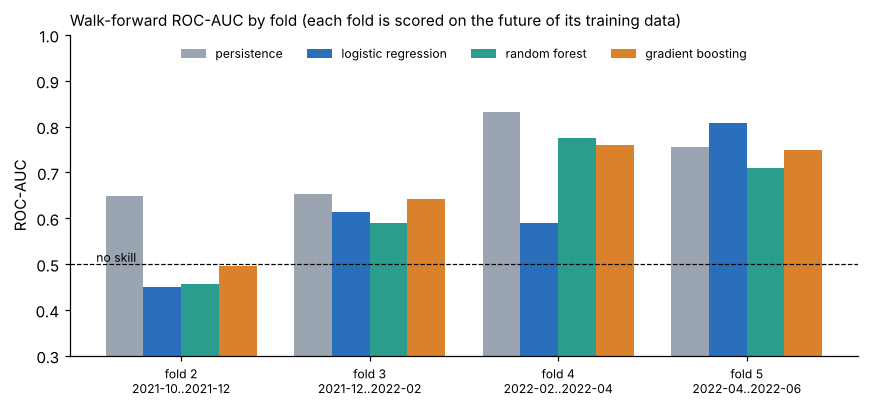

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = ["persistence", *LEARNED]
palette = {"persistence": "#9aa5b1", "logistic_regression": "#2a6fbb", "random_forest": "#2a9d8f", "gradient_boosting": "#d9822b"}
w = 0.2
for i, name in enumerate(names):
    ax.bar(np.arange(len(folds_df)) + (i - 1.5) * w, folds_df[f"{name}_auc"], w, color=palette[name], label=name.replace("_", " "))
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.text(-0.45, 0.505, "no skill", fontsize=8, ha="left")
ax.set_xticks(range(len(folds_df)), [f"fold {k}\n{r.test_from[:7]}..{r.test_to[:7]}" for k, r in folds_df.iterrows()], fontsize=8)
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.3, 1.0)
ax.set_title("Walk-forward ROC-AUC by fold (each fold is scored on the future of its training data)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
fig.tight_layout()
fig.savefig(FIG / "04_walk_forward_auc.png", dpi=130)
plt.show()

## 5. Save results
Outputs go to `notebooks/real_data/outputs/` only. `models/` is left alone: its checksums are verified by the backend
(`models/manifest.json`), and these models forecast rainfall, not floods.

In [8]:
joblib.dump({"models": models, "features": FEATURES, "scaler": fmeta["scaler"], "heavy_rain_mm": HEAVY},
            OUT / "rain_models_holdout.joblib")
test_pred = te[["region_id", "date", "y", "rainfall_mm", "target_rain_next_mm"]].copy()
for name, s in test_scores.items():
    test_pred[name] = s
test_pred.to_csv(OUT / "predictions_test.csv", index=False)
oof.to_csv(OUT / "predictions_walk_forward.csv", index=False)
(OUT / "metrics.json").write_text(json.dumps({
    "data_kind": "real", "target": fmeta["target"], "seed": SEED,
    "holdout_test": holdout, "holdout_bootstrap_ci": boot, "walk_forward": cv,
    "walk_forward_folds": folds, "positives": {"test": int(y_te.sum()), "walk_forward_pooled": int(oof["y"].sum())},
    "note": "Rainfall-hazard proxy on two stations / 12 months. Not flood-prediction accuracy.",
}, indent=2), encoding="utf-8")
print("saved metrics.json, predictions_test.csv, predictions_walk_forward.csv, rain_models_holdout.joblib")

saved metrics.json, predictions_test.csv, predictions_walk_forward.csv, rain_models_holdout.joblib
